# Paper run: training loss and Jacobian metrics

Loads the 200-epoch `paper_1gpu` metrics and the Jacobian eval of `checkpoint-last.pth`.

Field snapshots are the PNGs already written under `jacobian_paper_1gpu/plots/`. This notebook does not open `jacobian_fields.h5`.

In [6]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
from IPython.display import Image, Markdown, display

METRICS_CSV = Path("/pscratch/sd/d/divyam/hine_runs/paper_1gpu/csv/train_metrics.csv")
JAC_DIR = Path("/pscratch/sd/d/divyam/hine_runs/jacobian_paper_1gpu")
JAC_PLOTS = JAC_DIR / "plots"

print("metrics:", METRICS_CSV.exists(), METRICS_CSV)
print("jacobian:", JAC_DIR.exists(), JAC_DIR)

metrics: True /pscratch/sd/d/divyam/hine_runs/paper_1gpu/csv/train_metrics.csv
jacobian: True /pscratch/sd/d/divyam/hine_runs/jacobian_paper_1gpu


## Train and validation loss

epochs 0..199  n=200
final train=0.0792657  val=0.0672615


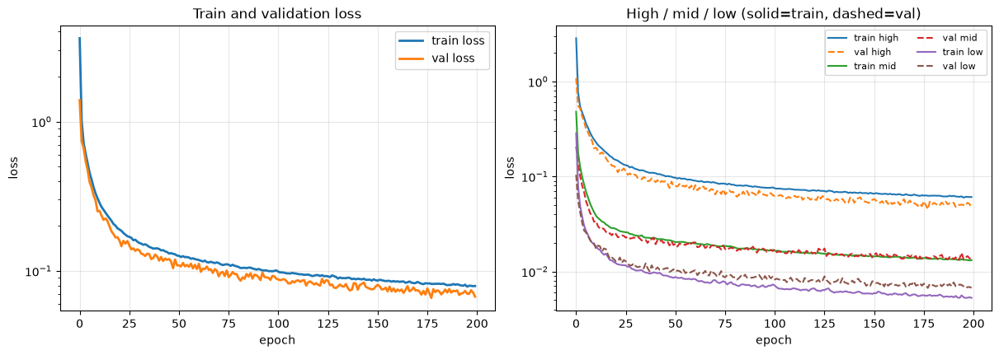

In [7]:
data = np.genfromtxt(METRICS_CSV, delimiter=",", names=True)
epoch = data["epoch"]
print(f"epochs {int(epoch[0])}..{int(epoch[-1])}  n={len(epoch)}")
print(f"final train={data['loss'][-1]:.6g}  val={data['val_loss'][-1]:.6g}")

fig, axes = plt.subplots(1, 2, figsize=(12, 4.2), constrained_layout=True)

ax = axes[0]
ax.plot(epoch, data["loss"], label="train loss", lw=2)
ax.plot(epoch, data["val_loss"], label="val loss", lw=2)
ax.set_xlabel("epoch")
ax.set_ylabel("loss")
ax.set_yscale("log")
ax.set_title("Train and validation loss")
ax.legend()
ax.grid(True, alpha=0.3)

ax = axes[1]
ax.plot(epoch, data["high_loss"], label="train high", lw=1.5)
ax.plot(epoch, data["val_high_loss"], label="val high", lw=1.5, ls="--")
ax.plot(epoch, data["mid_loss"], label="train mid", lw=1.5)
ax.plot(epoch, data["val_mid_loss"], label="val mid", lw=1.5, ls="--")
ax.plot(epoch, data["low_loss"], label="train low", lw=1.5)
ax.plot(epoch, data["val_low_loss"], label="val low", lw=1.5, ls="--")
ax.set_xlabel("epoch")
ax.set_ylabel("loss")
ax.set_yscale("log")
ax.set_title("High / mid / low (solid=train, dashed=val)")
ax.legend(fontsize=8, ncol=2)
ax.grid(True, alpha=0.3)
plt.show()


## Jacobian summary and scalar metrics

Autoregressive curves are solid. Teacher-forced curves are dashed.

HINE Jacobian smoke analysis
checkpoint: /pscratch/sd/d/divyam/hine_runs/paper_1gpu/checkpoint-last.pth
eval_dir: /global/homes/d/divyam/TACSLAB/eval
raw_mat_count: 13380
kept_frames (index%5==0): 2676
skipped_by_keep_rule: 10704
num_starts: 4
starts: [0, 885, 1770, 2655]
file_indices: [91625, 96050, 100475, 104900]
horizon: 20
power_iters: 15
eps: 0.001
eps_check: 0.01
eps_check_radius(0.001)=78.9808
eps_check_radius(0.01)=8.71609

start=0 file_index=91625
  tf final residual MSE: 0.00220217
  tf max |lambda|:       80.5421
  ar final MSE:          0.0775371
  ar max |lambda|:       80.8136

start=885 file_index=96050
  tf final residual MSE: 0.00277894
  tf max |lambda|:       79.2173
  ar final MSE:          0.0423276
  ar max |lambda|:       79.4275

start=1770 file_index=100475
  tf final residual MSE: 0.00269723
  tf max |lambda|:       81.0875
  ar final MSE:          0.0812917
  ar max |lambda|:       79.9467

start=2655 file_index=104900
  tf final residual MSE: 0.00492208
  t

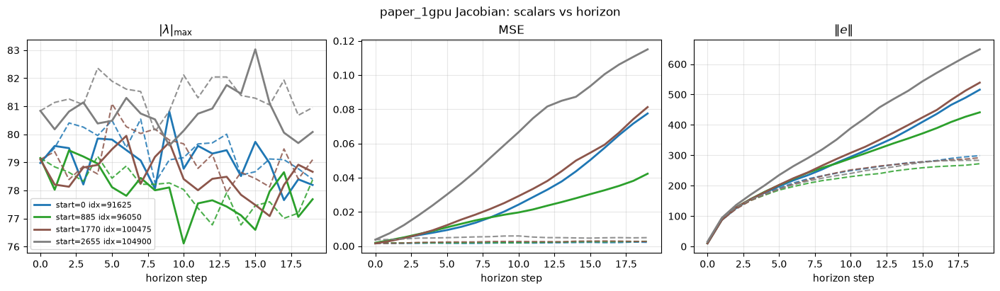

radius(eps=0.001) = 78.9808
radius(eps=0.01) = 8.71609


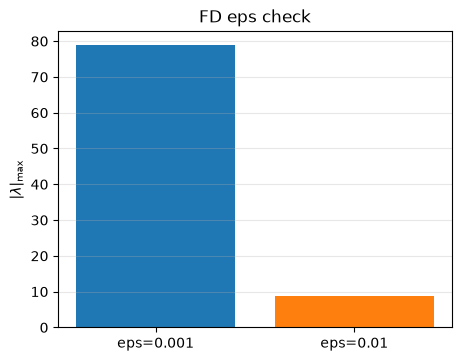

In [8]:
print((JAC_DIR / "summary.txt").read_text())

traj = np.load(JAC_DIR / "trajectories.npz")
starts = traj["starts"]
file_indices = traj["file_indices"]
t = np.arange(traj["ar_radius"].shape[1])
labels = [f"start={int(s)} idx={int(fi)}" for s, fi in zip(starts, file_indices)]
cmap = plt.cm.tab10(np.linspace(0, 1, len(starts), endpoint=False))

fig, axes = plt.subplots(1, 3, figsize=(14, 4), constrained_layout=True)
panels = [
    (r"$|\lambda|_{\max}$", "ar_radius", "tf_radius"),
    ("MSE", "ar_mse", "tf_residual_mse"),
    (r"$\|e\|$", "ar_pert_norm", "tf_pert_norm"),
]
for ax, (title, ar_key, tf_key) in zip(axes, panels):
    for i, (c, lab) in enumerate(zip(cmap, labels)):
        ax.plot(t, traj[ar_key][i], color=c, lw=2, label=lab)
        ax.plot(t, traj[tf_key][i], color=c, lw=1.5, ls="--", alpha=0.85)
    ax.set_xlabel("horizon step")
    ax.set_title(title)
    ax.grid(True, alpha=0.3)
axes[0].legend(fontsize=8, loc="best")
fig.suptitle("paper_1gpu Jacobian: scalars vs horizon")
plt.show()

eps = float(traj["eps"])
eps_check = float(traj["eps_check"])
r_eps = float(traj["radius_eps"])
r_eps_check = float(traj["radius_eps_check"])
print(f"radius(eps={eps:g}) = {r_eps:.6g}")
print(f"radius(eps={eps_check:g}) = {r_eps_check:.6g}")

fig, ax = plt.subplots(figsize=(4.5, 3.5), constrained_layout=True)
ax.bar([f"eps={eps:g}", f"eps={eps_check:g}"], [r_eps, r_eps_check], color=["C0", "C1"])
ax.set_ylabel(r"$|\lambda|_{\max}$")
ax.set_title("FD eps check")
ax.grid(True, axis="y", alpha=0.3)
plt.show()

## Saved field and latent figures

These are the PNGs from the CPU plot job. They are displayed from disk, not recomputed from the HDF5.

**scalars_vs_horizon.png**

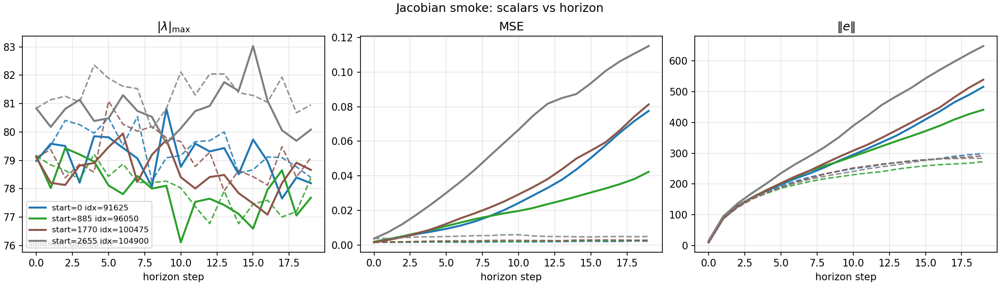

**eps_check.png**

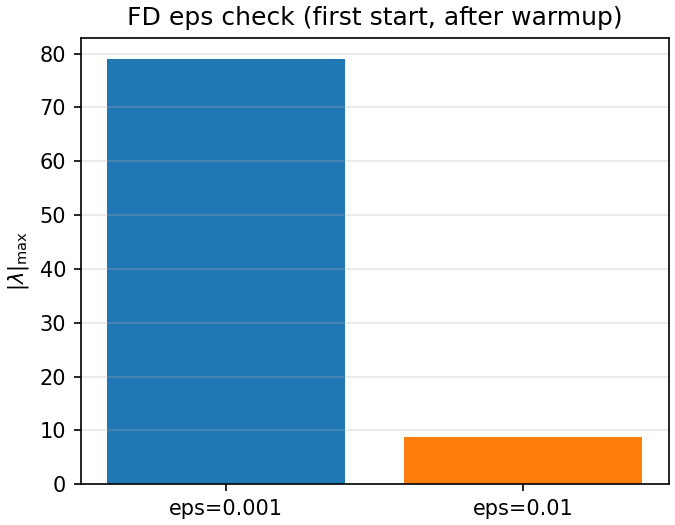

**latents_start0_idx91625.png**

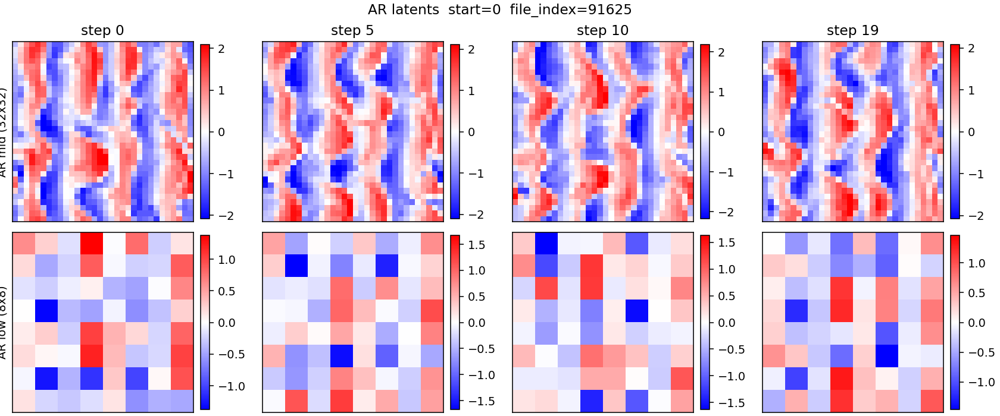

**fields_start0_idx91625.png**

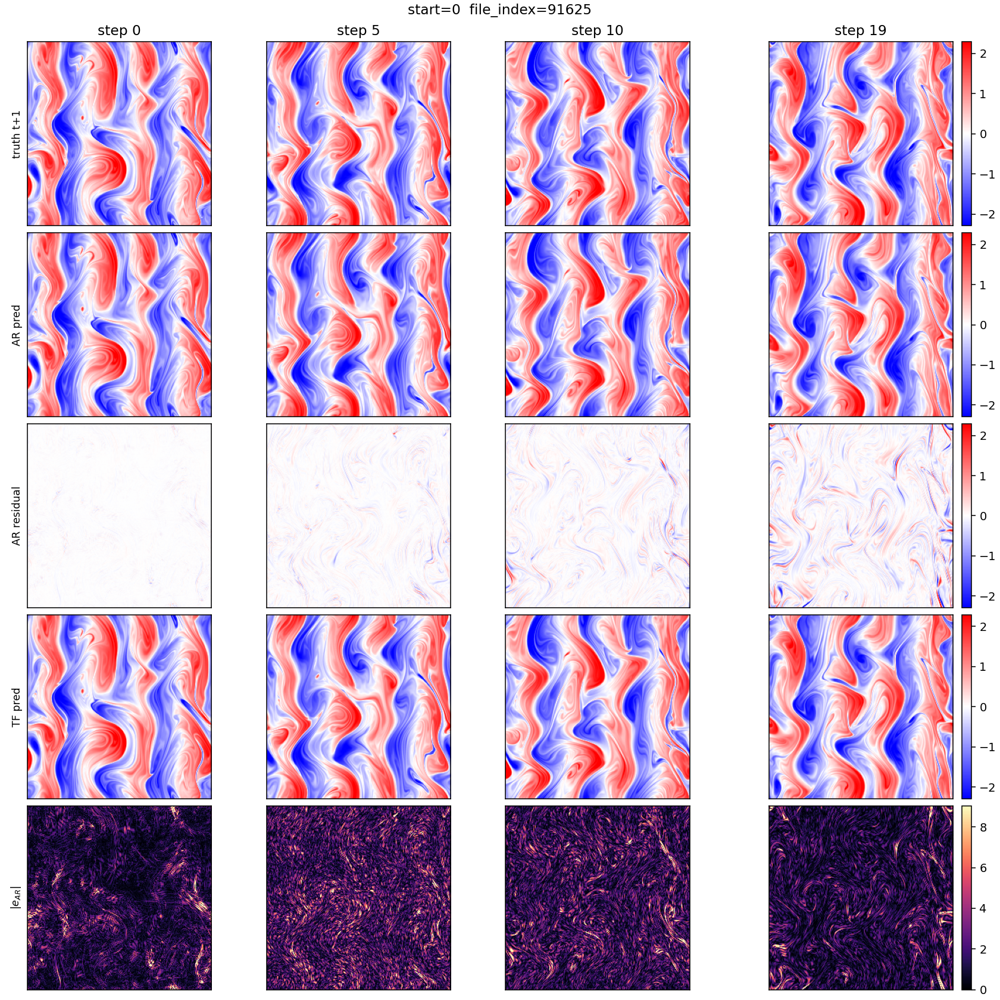

**fields_start885_idx96050.png**

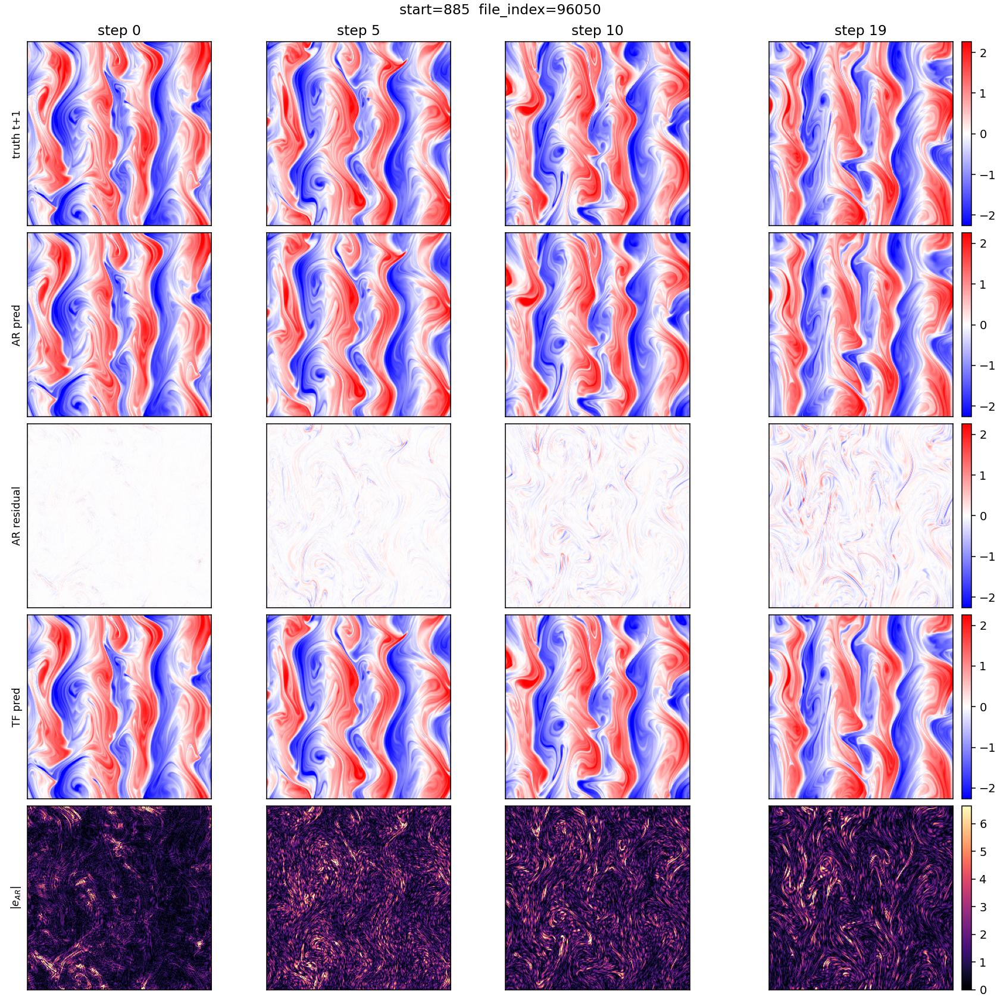

**fields_start1770_idx100475.png**

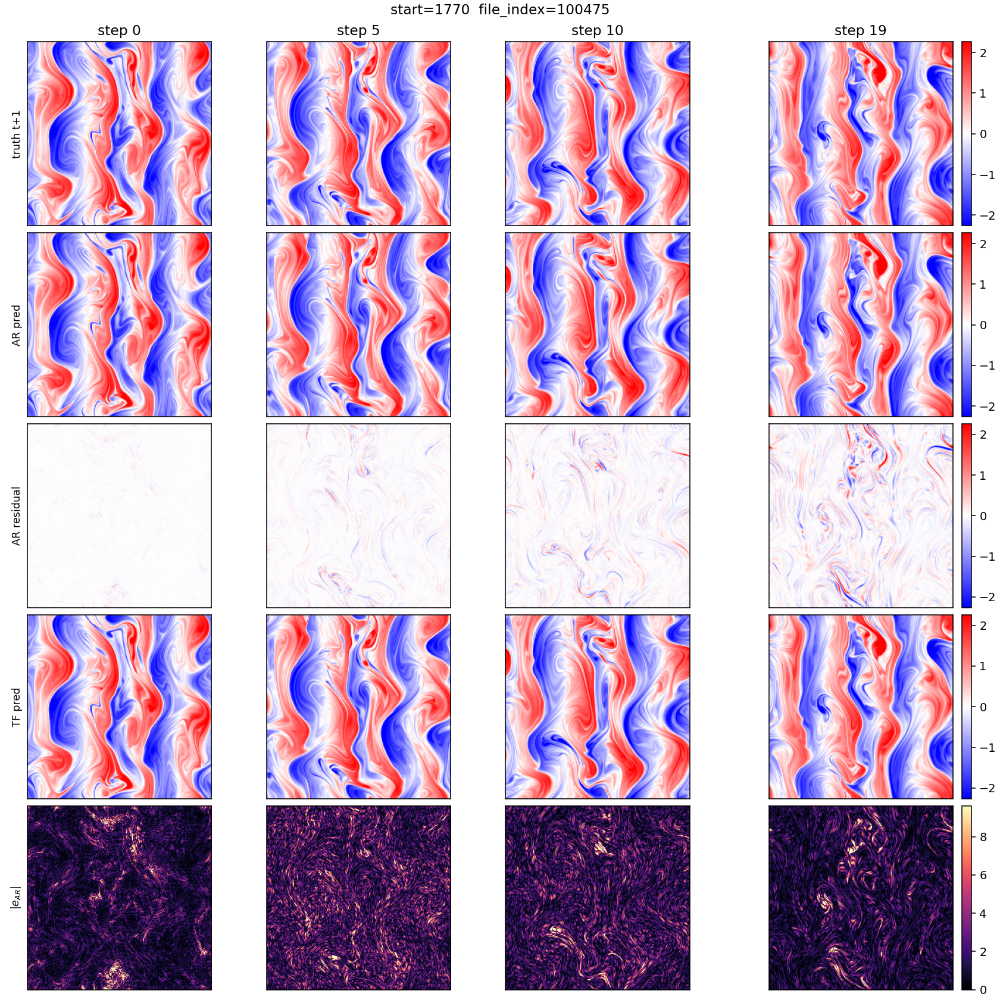

**fields_start2655_idx104900.png**

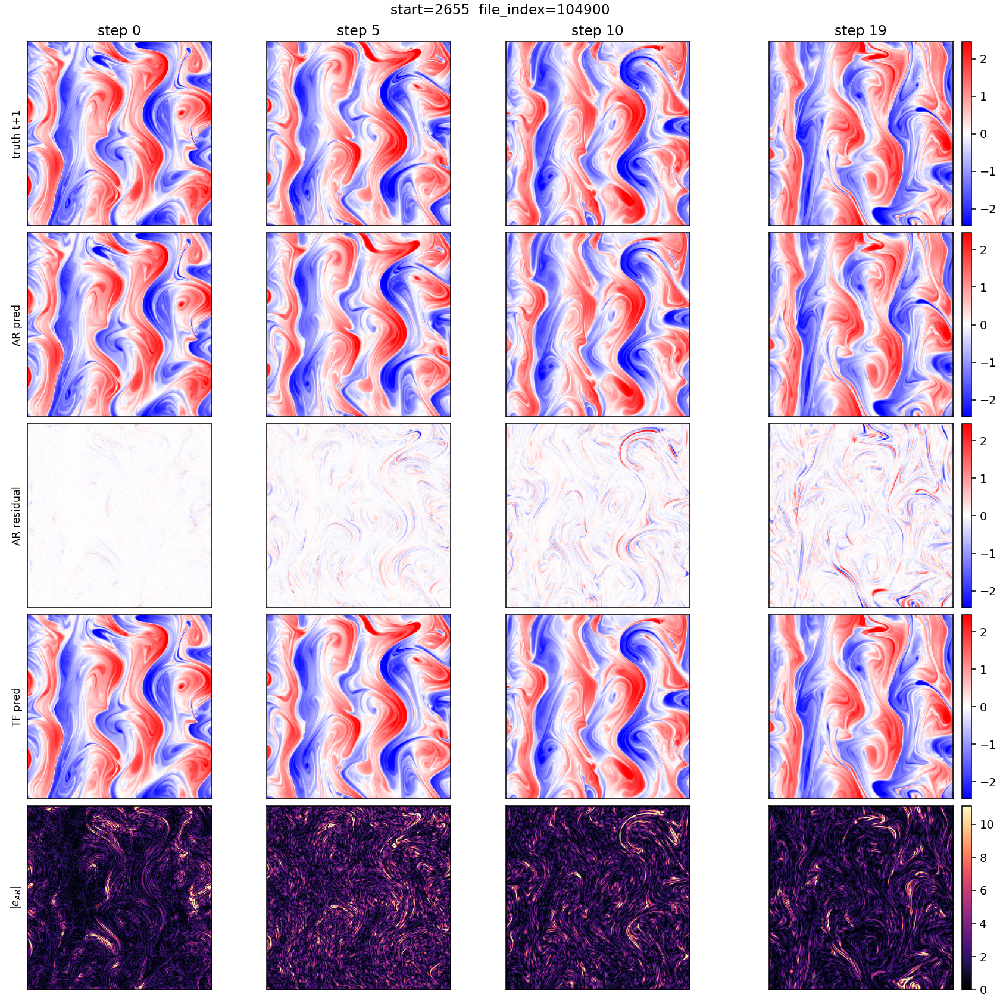

In [9]:
names = [
    "scalars_vs_horizon.png",
    "eps_check.png",
    "latents_start0_idx91625.png",
    "fields_start0_idx91625.png",
    "fields_start885_idx96050.png",
    "fields_start1770_idx100475.png",
    "fields_start2655_idx104900.png",
]
for name in names:
    path = JAC_PLOTS / name
    display(Markdown(f"**{name}**"))
    display(Image(filename=str(path)))

## Jacobian eigenvalues (Argand)

Dominant eigenvalues of the direct-step map, saved under
`/pscratch/sd/d/divyam/hine_runs/jacobian_paper_1gpu/eigs_steps/`.
13 of 16 spectra were written before the 15-minute limit: starts 0, 885, and 1770
at steps 0, 5, 10, and 19, and start 2655 at step 0 only.
The all-steps directory was not created.

Figures below are the PNGs in `eigs_steps/plots/`. Re-running this cell reloads them from disk.


### `eigs_steps`

(no summary yet: /pscratch/sd/d/divyam/hine_runs/jacobian_paper_1gpu/eigs_steps/summary.txt)


**eigs_summary.png**

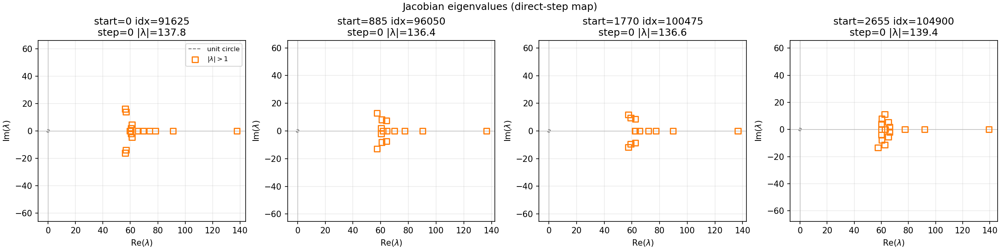

**eigs_lambda_max_by_start.png**

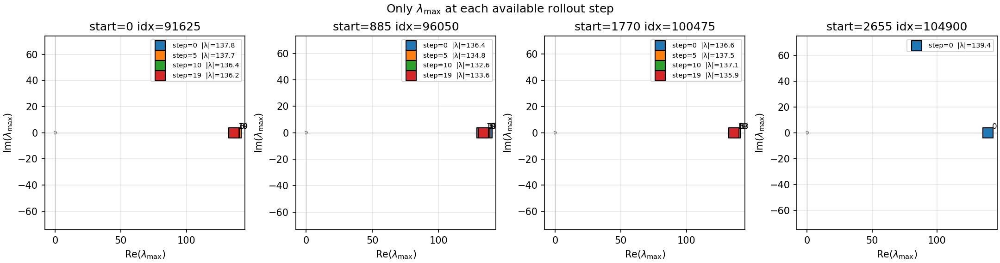

**eigs_lambda_max_summary.png**

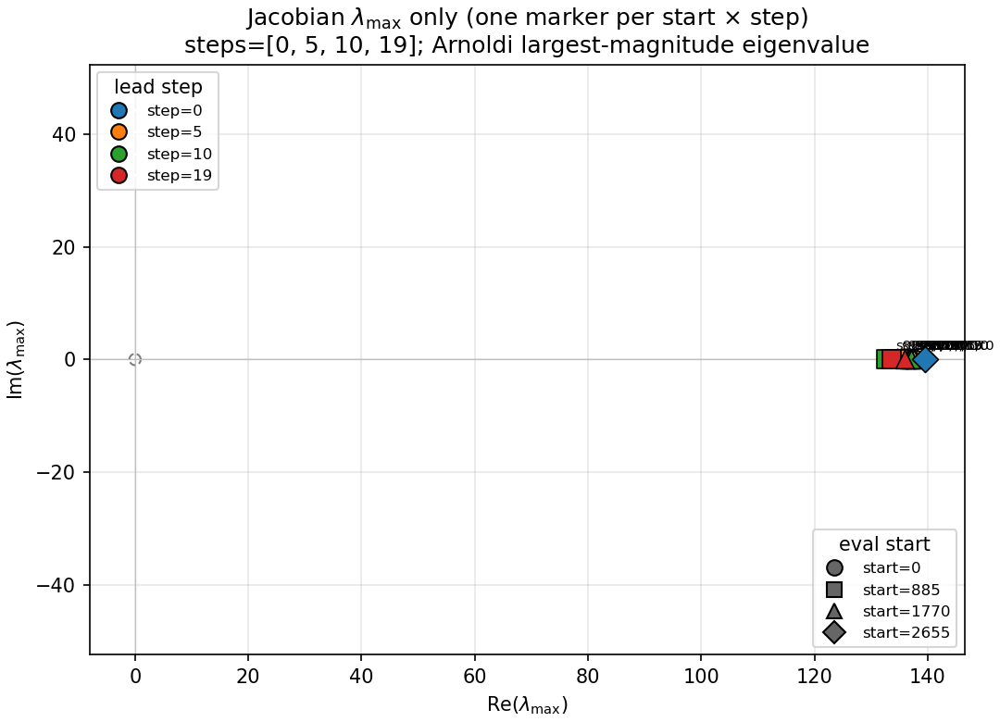

**eigs_start0_idx91625_step0.png**

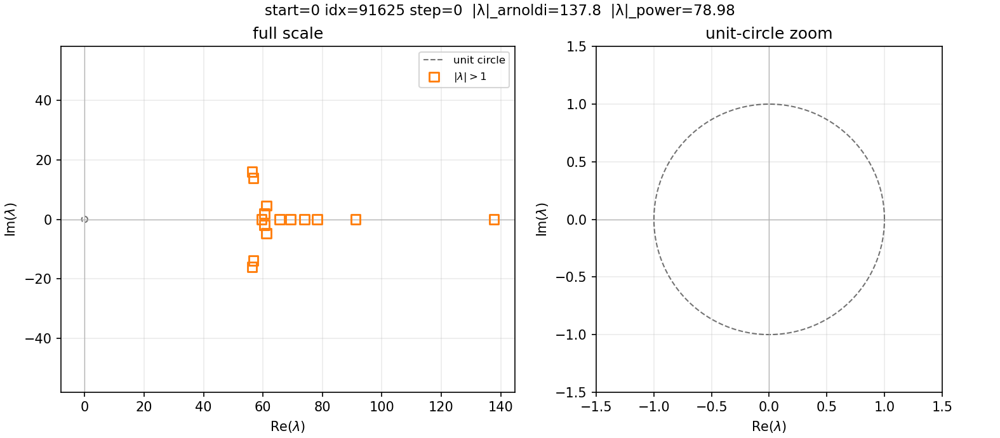

**eigs_start0_idx91625_step10.png**

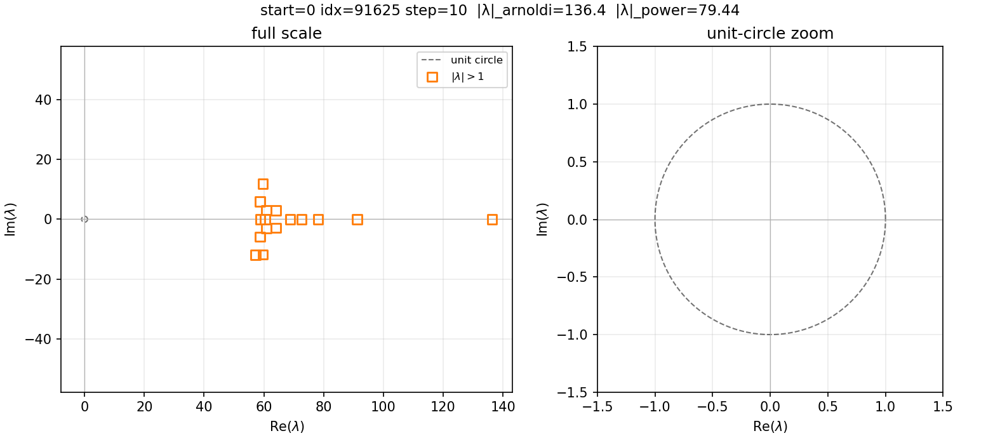

**eigs_start0_idx91625_step19.png**

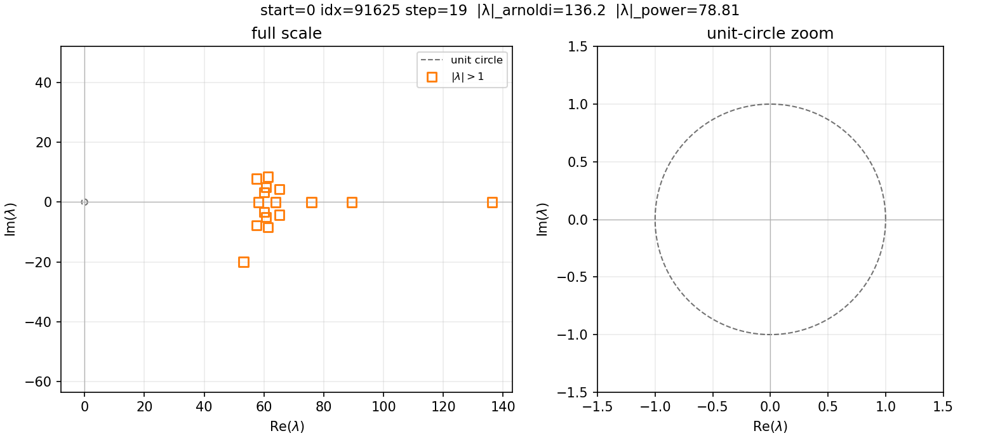

**eigs_start0_idx91625_step5.png**

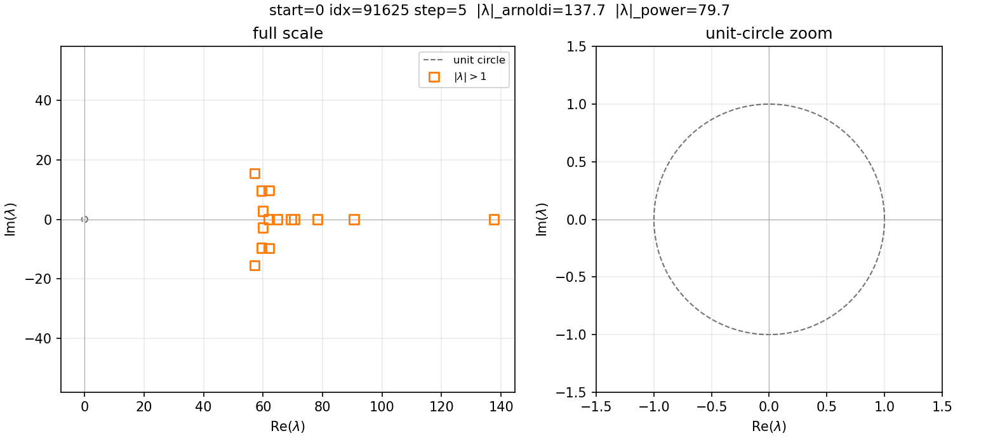

**eigs_start1770_idx100475_step0.png**

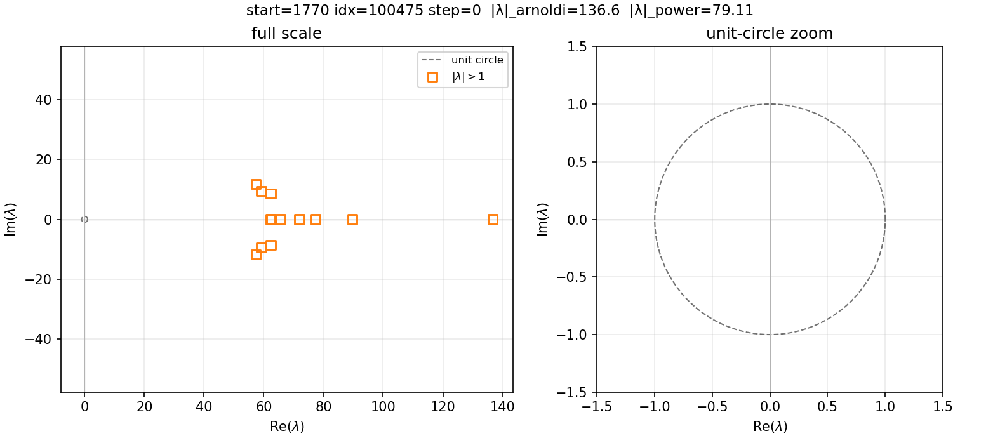

**eigs_start1770_idx100475_step10.png**

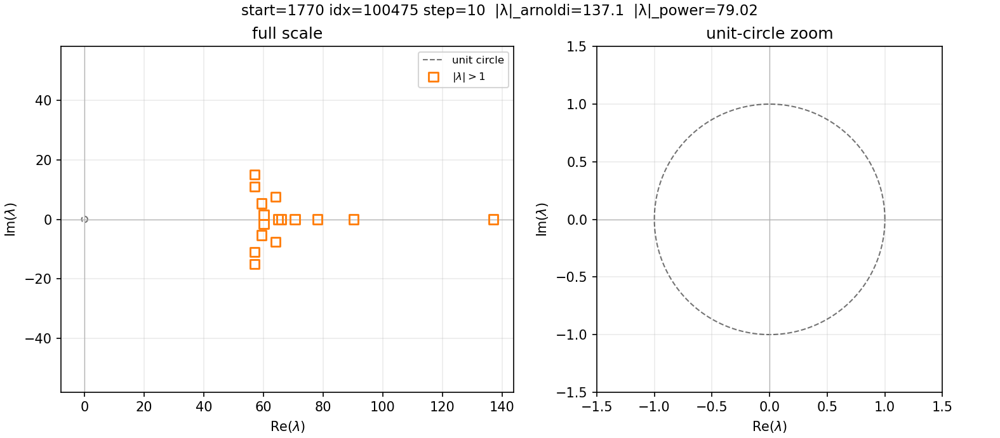

**eigs_start1770_idx100475_step19.png**

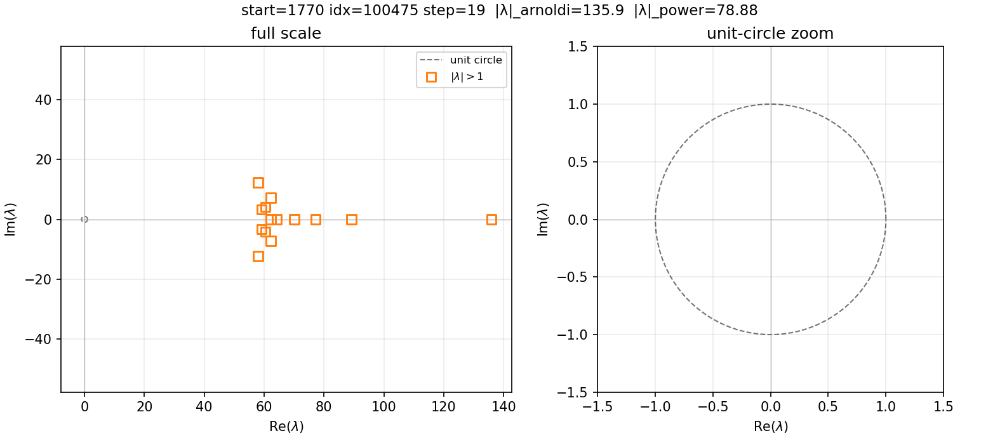

**eigs_start1770_idx100475_step5.png**

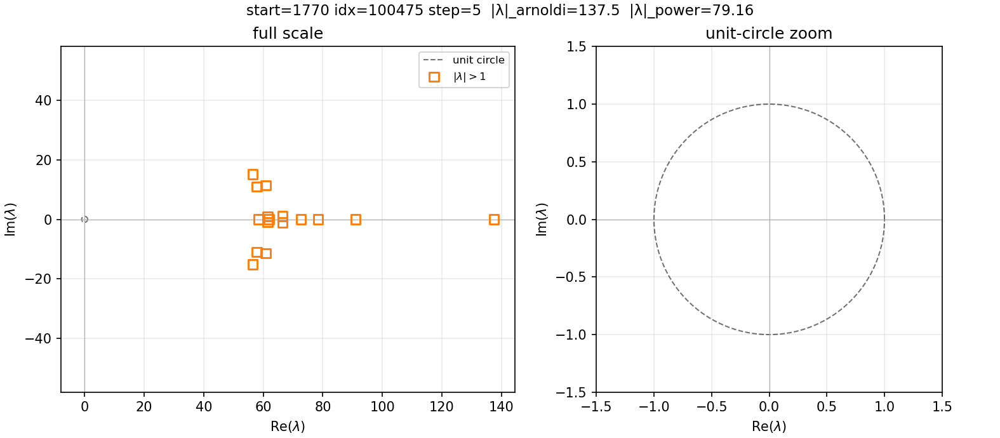

**eigs_start2655_idx104900_step0.png**

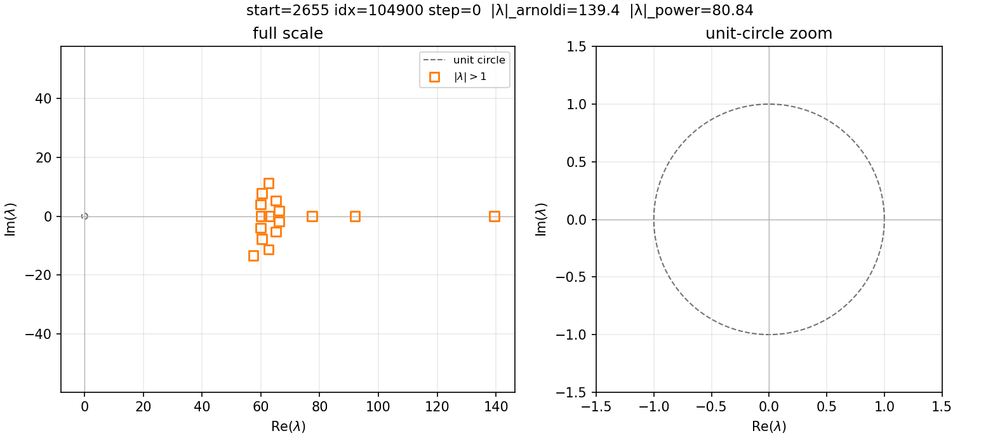

**eigs_start885_idx96050_step0.png**

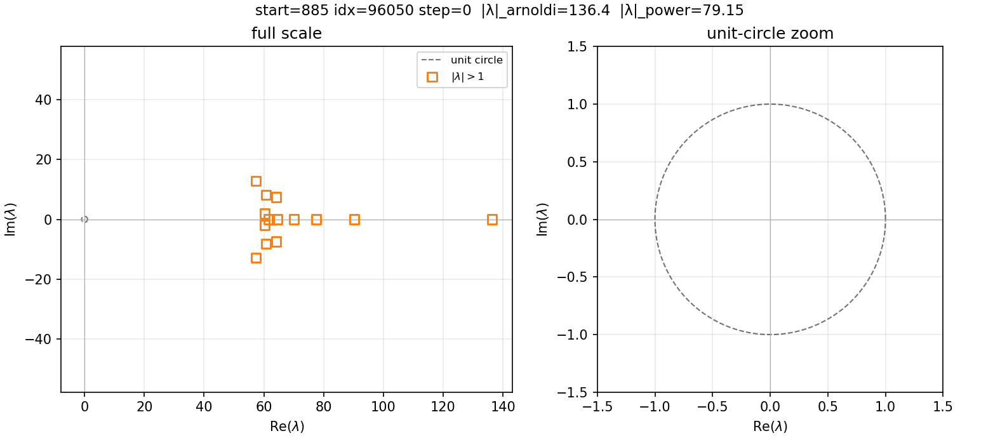

**eigs_start885_idx96050_step10.png**

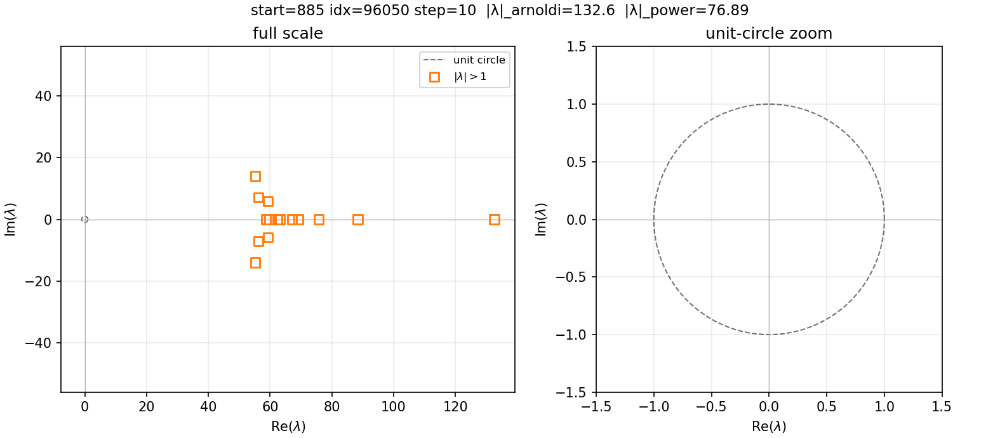

**eigs_start885_idx96050_step19.png**

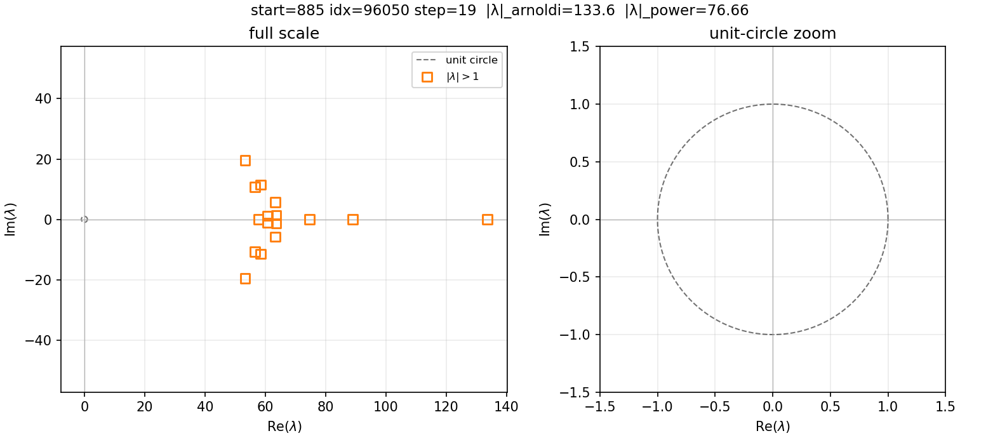

**eigs_start885_idx96050_step5.png**

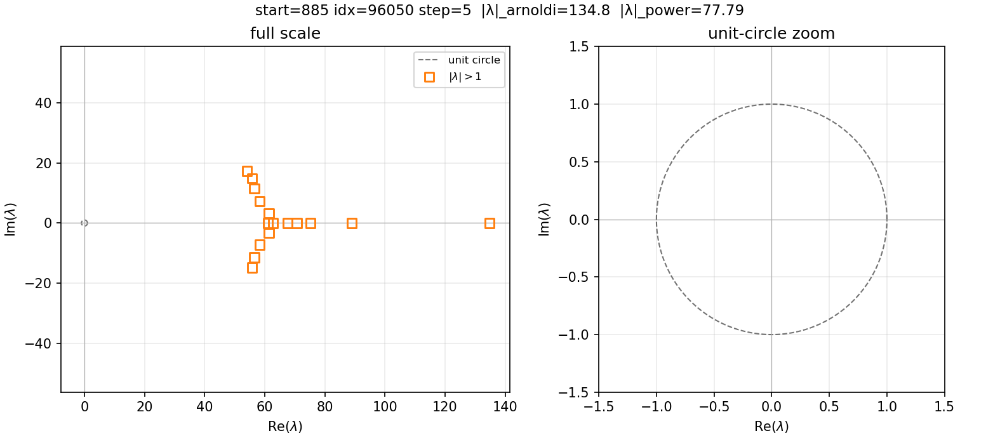

### `eigs_all`

(no summary yet: /pscratch/sd/d/divyam/hine_runs/jacobian_paper_1gpu/eigs_all/summary.txt)
(no plots yet: /pscratch/sd/d/divyam/hine_runs/jacobian_paper_1gpu/eigs_all/plots)


In [10]:
EIGS_DIRS = [
    JAC_DIR / "eigs_steps",
    JAC_DIR / "eigs_all",
]

for eigs_dir in EIGS_DIRS:
    plot_dir = eigs_dir / "plots"
    display(Markdown(f"### `{eigs_dir.name}`"))
    summary = eigs_dir / "summary.txt"
    if summary.is_file():
        print(summary.read_text()[:2000])
    else:
        print(f"(no summary yet: {summary})")
    if not plot_dir.is_dir():
        print(f"(no plots yet: {plot_dir})")
        continue
    pngs = sorted(plot_dir.glob("*.png"))
    if not pngs:
        print(f"(empty plots dir: {plot_dir})")
        continue
    # Prefer summary first, then per-spectrum figures.
    ordered = sorted(
        pngs,
        key=lambda p: (0 if p.name == "eigs_summary.png" else 1, p.name),
    )
    for path in ordered:
        display(Markdown(f"**{path.name}**"))
        display(Image(filename=str(path)))
